# Notebook 81: Normalized Decorrelation Scale & Multi-Basin Comparison
### Cross-Basin Normalization of Oxygen Decorrelation Scales (Tokyo Bay, Ise Bay, Osaka Bay, Seto Inland Sea)

---

## 1. Scientific Background & Rationale
Different semi-enclosed coastal basins in Japan vary widely in geometric size ($R_{eq} = \sqrt{A/\pi} \sim 15 - 85$ km) and monitoring network density (median nearest-neighbor station distance $d_{NN} \sim 4 - 20$ km). Directly comparing raw decorrelation scales ($L_d$) across basins can be misleading because:
1. **Basin-Size Boundary Constraints (Finite-Size Effect):** $L_d$ cannot physically exceed the basin's geometric dimension ($R_{eq}$ or basin diameter).
2. **Monitoring Density Artifacts (Sampling Limit):** If the station spacing ($d_{NN}$) is larger than the true physical decorrelation scale, the fitted scale may simply reflect the minimum station spacing rather than true oceanographic coherence.

To enable rigorous cross-basin comparisons and isolate the physical spatial scale of hypoxia, this notebook formulates three dimensionless normalization metrics:

| Metric | Formula | Physical Meaning & Scientific Role |
|---|---|---|
| **Relative Coherence Scale ($\eta$)** | $\eta = \dfrac{L_d}{R_{eq}}$ | Basin-size normalized scale ($0 < \eta \le 1$). Measures what fraction of the basin fluctuates coherently. $\eta \to 1$ indicates basin-wide coherence; $\eta \ll 1$ indicates localized sub-mesoscale phenomena. |
| **Sampling Margin / Resolution Ratio ($\Theta$)** | $\Theta = \dfrac{L_d}{d_{NN}}$ | Nyquist sampling quality flag. If $\Theta \ge 1.0$, the decorrelation scale is physically resolved by the station network. If $\Theta < 1.0$, the apparent scale is unresolved / sampling-limited. |
| **Bounded Spatial Index ($\Phi$)** | $\Phi = \dfrac{L_d - d_{NN}}{R_{eq} - d_{NN}}$ | Rescales $L_d$ into $[0, 1]$ between the minimum resolvable station spacing ($d_{NN}$) and physical basin boundary ($R_{eq}$). |

### Basin Grouping & Geometric Definitions (Matching Notebook 58)
Following `step0_sandbox/58_Decorrelation_Scale_Analysis_multiple_bay_basin_overview.ipynb`, we evaluate the 4 primary coastal water bodies:
1. **Tokyo Bay** (`watermass_name == 'Tokyo Bay'`)
2. **Ise Bay** (`watermass_name == 'Ise Bay'` / alias `Ise Mikawa Bay`)
3. **Osaka Bay** (`division == 'Osaka Bay'`)
4. **Seto Inland Sea** (`watermass_name == 'Seto Inland Sea'`)

We compute the equivalent radius using two independent area definitions:
- **Shapefile Water Area ($A_{\text{water}}$):** Real GIS water masks from pipeline step 2 / notebooks 55 & 56 projected in UTM 53N (`EPSG:32653`), yielding $R_{eq,\text{shape}} = \sqrt{A_{\text{water}}/\pi}$.
- **Station Convex Hull Area ($A_{\text{hull}}$):** Minimum bounding convex polygon enclosing all monitoring stations, yielding $R_{eq,\text{hull}} = \sqrt{A_{\text{hull}}/\pi}$.


In [1]:
# --- 1. Imports & Environment Setup ---
import os
import sys
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point, MultiPolygon, Polygon
from scipy.spatial import ConvexHull

# Resolve project root (sits 1 level above step0_sandbox)
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig

# Apply global styling
MappingConfig.apply_global_plot_styles()
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
print(f"Project root resolved to: {project_root}")


Project root resolved to: /home/reyha/SIS_Analysis_WSL


## 2. Output Directory & Dynamic Parameter Configuration
In accordance with `.agent/global_rule.md`:
- All outputs are stored in `figures/step0_sandbox/81_normalized_decorrelation_scale_basin_comparison/`.
- Prior to execution, any existing output folder is wiped clean and recreated.
- Execution parameters are loaded from `81_parameters.csv`. If this file is missing, default values are written automatically, ensuring the notebook remains independently runnable.


In [2]:
# --- 2. Output Directory & Dynamic Parameters ---
notebook_name = "81_normalized_decorrelation_scale_basin_comparison"
output_dir = ProjectPaths.FIGURES_DIR / "step0_sandbox" / notebook_name

# Wipe and recreate output directory cleanly
if output_dir.exists():
    shutil.rmtree(output_dir, ignore_errors=True)
output_dir.mkdir(parents=True, exist_ok=True)

param_file = output_dir / "81_parameters.csv"

# Write default parameters CSV if missing
if not param_file.exists():
    default_params = {
        'parameter_name': [
            'season',
            'saisuipoin_id',
            'layer_name',
            'min_periods',
            'r_crit_alpha',
            'distance_cutoff_km',
            'min_stations',
            'radius_source',
            'subsample_sizes',
            'subsample_iterations',
            'random_seed'
        ],
        'value': [
            'Summer',
            2,
            'bottom',
            15,
            0.01,
            100.0,
            5,
            'shapefile',
            '25,20,15,10,8',
            20,
            42
        ]
    }
    pd.DataFrame(default_params).to_csv(param_file, index=False)

# Load parameters
df_params = pd.read_csv(param_file)
PARAMS = dict(zip(df_params['parameter_name'], df_params['value']))

# Parse types
TARGET_SEASON = str(PARAMS.get('season', 'Summer'))
SAISUIPOIN_ID = int(PARAMS.get('saisuipoin_id', 2))
LAYER_NAME = str(PARAMS.get('layer_name', 'bottom'))
MIN_PERIODS = int(PARAMS.get('min_periods', 15))
R_CRIT_ALPHA = float(PARAMS.get('r_crit_alpha', 0.01))
DISTANCE_CUTOFF_KM = float(PARAMS.get('distance_cutoff_km', 100.0))
MIN_STATIONS = int(PARAMS.get('min_stations', 5))
RADIUS_SOURCE = str(PARAMS.get('radius_source', 'shapefile'))
SUBSAMPLE_SIZES = [int(s.strip()) for s in str(PARAMS.get('subsample_sizes', '25,20,15,10,8')).split(',')]
SUBSAMPLE_ITER = int(PARAMS.get('subsample_iterations', 20))
RANDOM_SEED = int(PARAMS.get('random_seed', 42))

print(f"Loaded {len(PARAMS)} parameters from {param_file.name}:")
for k, v in PARAMS.items():
    print(f"  {k}: {v}")


Loaded 11 parameters from 81_parameters.csv:
  season: Summer
  saisuipoin_id: 2
  layer_name: bottom
  min_periods: 15
  r_crit_alpha: 0.01
  distance_cutoff_km: 100.0
  min_stations: 5
  radius_source: shapefile
  subsample_sizes: 25,20,15,10,8
  subsample_iterations: 20
  random_seed: 42


## 3. Data Loading & Defensive Validation
We load the pre-processed spatial stations (`merged_gdf.feather`) and the annual time series matrix (`yearly_do_df.csv`) for the specified season and layer (`Summer`, `bottom`).
Explicit file-existence checks verify that prerequisites are available before proceeding.


In [3]:
# --- 3. Load Datasets with Defensive Checks ---
merged_data_path = ProjectPaths.MERGED_DATA_FILE
yearly_do_path = ProjectPaths.get_subset_dir(TARGET_SEASON, LAYER_NAME) / "yearly_do_df.csv"

if not merged_data_path.exists():
    raise FileNotFoundError(f"Missing required merged data: {merged_data_path}")
if not yearly_do_path.exists():
    raise FileNotFoundError(f"Missing required yearly DO time series: {yearly_do_path}")

print(f"Loading stations from {merged_data_path.name}...")
merged_gdf = gpd.read_feather(merged_data_path)

print(f"Loading yearly DO matrix from {yearly_do_path.name}...")
yearly_do_df = pd.read_csv(yearly_do_path, index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)

print(f"Yearly DO table: {yearly_do_df.shape[0]} stations x {yearly_do_df.shape[1]} years")
print(f"Total merged records: {len(merged_gdf):,}")


Loading stations from merged_gdf.feather...


Loading yearly DO matrix from yearly_do_df.csv...


Yearly DO table: 185 stations x 43 years
Total merged records: 62,738


## 4. Basin Definitions & Boundary Shapefile Mapping
We configure the 4 coastal water masses matching Notebook 58:
- **Tokyo Bay:** `watermass_name == 'Tokyo Bay'`
- **Ise Bay:** `watermass_name == 'Ise Bay'` (including alias `'Ise Mikawa Bay'`)
- **Osaka Bay:** `division == 'Osaka Bay'`
- **Seto Inland Sea:** `watermass_name == 'Seto Inland Sea'`

For boundary shapefiles, we reference the official GIS water mass polygon files used in pipeline step 2 and sandbox notebooks 55 & 56 (`data/boundaries/SIS water mass polygon/`). For Osaka Bay (a sub-basin within the Seto Inland Sea polygon), the water mask is clipped to the station convex hull buffered by 5 km, consistent with the `setup_diffusion_grid` logic in notebooks 55 and 56.


In [4]:
# --- 4. Basin Configuration & Shapefile Mapping ---
boundaries_base = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon"

basins_config = {
    'Tokyo Bay': {
        'filter_type': 'watermass_name',
        'filter_value': 'Tokyo Bay',
        'shapefile': boundaries_base / 'sea_area_mask_Tokyo.shp',
        'clip_to_stations': False
    },
    'Ise Bay': {
        'filter_type': 'watermass_name',
        'filter_value': 'Ise Bay',
        'shapefile': boundaries_base / 'sea_area_mask_Ise.shp',
        'clip_to_stations': False
    },
    'Osaka Bay': {
        'filter_type': 'division',
        'filter_value': 'Osaka Bay',
        'shapefile': boundaries_base / 'sea_area_mask_sis_simplified.shp',
        'clip_to_stations': True
    },
    'Seto Inland Sea': {
        'filter_type': 'watermass_name',
        'filter_value': 'Seto Inland Sea',
        'shapefile': boundaries_base / 'sea_area_mask_sis_simplified.shp',
        'clip_to_stations': False
    }
}

print(f"Configured {len(basins_config)} basins for analysis:")
for b_name, b_info in basins_config.items():
    shp_exists = b_info['shapefile'].exists()
    print(f"  - {b_name:16s}: shapefile exists={shp_exists} ({b_info['shapefile'].name})")


Configured 4 basins for analysis:
  - Tokyo Bay       : shapefile exists=True (sea_area_mask_Tokyo.shp)
  - Ise Bay         : shapefile exists=True (sea_area_mask_Ise.shp)
  - Osaka Bay       : shapefile exists=True (sea_area_mask_sis_simplified.shp)
  - Seto Inland Sea : shapefile exists=True (sea_area_mask_sis_simplified.shp)


## 5. Core Fitting & Geometric Analytical Functions
This cell implements the self-contained functions for:
1. **Gaussian Decorrelation Fitting:**
   $$r(x) = A e^{-(x / \Delta x)^2} + B, \quad B = 1 - A$$
   Critical threshold $r_{\text{crit}}$ is determined via the two-tailed Student's $t$-distribution at $\alpha = 0.01$. Decorrelation scale $L_d$ is the distance where $r(L_d) = r_{\text{crit}}$:
   $$L_d = \Delta x \sqrt{-\ln\left(\frac{r_{\text{crit}} - B}{A}\right)}$$
2. **Basin Geometry ($R_{eq}$ & Area):**
   Projects geometries into UTM 53N (`EPSG:32653`) and calculates both shapefile water area ($A_{\text{water}}$) and station network convex hull area ($A_{\text{hull}}$), deriving equivalent radii $R_{eq} = \sqrt{A/\pi}$.


In [5]:
# --- 5. Core Analytical Functions ---

def gaussian_model_with_offset(x, A, dx):
    """Gaussian spatial decorrelation model with offset B = 1 - A."""
    return A * np.exp(-(x / dx)**2) + (1.0 - A)

def calculate_r_crit(n, alpha=0.01):
    """Calculates critical correlation threshold using t-distribution at alpha level."""
    if n < 3:
        return 1.0
    df = n - 2
    t_crit = stats.t.ppf(1.0 - alpha / 2.0, df)
    return np.sqrt(t_crit**2 / (t_crit**2 + df))

def compute_basin_geometry(stns_utm, shapefile_path, clip_to_stations=False):
    """
    Computes both shapefile-derived water area and station convex-hull area in UTM 53N.
    Returns dictionary with area [km2] and equivalent radii [km].
    """
    coords = np.array([(geom.x, geom.y) for geom in stns_utm.geometry])
    hull = ConvexHull(coords)
    hull_area_km2 = hull.volume / 1e6  # In 2D, hull.volume is area in m2
    r_eq_hull_km = np.sqrt(hull_area_km2 / np.pi)

    shape_area_km2 = np.nan
    r_eq_shape_km = np.nan
    if shapefile_path.exists():
        water_gdf = gpd.read_file(shapefile_path)
        if water_gdf.crs != 'EPSG:32653':
            water_gdf = water_gdf.to_crs('EPSG:32653')
            
        if clip_to_stations:
            hull_poly = Polygon(coords[hull.vertices]).buffer(5000.0)
            clipped_gdf = gpd.clip(water_gdf, hull_poly)
            shape_area_km2 = clipped_gdf.geometry.area.sum() / 1e6
        else:
            shape_area_km2 = water_gdf.geometry.area.sum() / 1e6
        r_eq_shape_km = np.sqrt(shape_area_km2 / np.pi)

    return {
        'hull_area_km2': hull_area_km2,
        'r_eq_hull_km': r_eq_hull_km,
        'shape_area_km2': shape_area_km2,
        'r_eq_shape_km': r_eq_shape_km
    }

def fit_station_decorrelation(yearly_do_basin, dist_matrix_km, target_station, min_periods=15, cutoff_km=100.0, alpha=0.01):
    """
    Fits Gaussian decorrelation curve for a single target station.
    Returns dict with L_d, d_nn, R2, or None if fit fails.
    """
    target_series = yearly_do_basin.loc[target_station]
    corrs = yearly_do_basin.corrwith(target_series, axis=1, drop=True)

    valid_stats = []
    for neighbor in yearly_do_basin.index:
        neigh_series = yearly_do_basin.loc[neighbor]
        valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
        if valid_count >= min_periods:
            if neighbor == target_station:
                c_val, d_val = 1.0, 0.0
            else:
                c_val = corrs[neighbor]
                d_val = dist_matrix_km.loc[target_station, neighbor]
            if not np.isnan(c_val) and not np.isnan(d_val) and d_val <= cutoff_km:
                valid_stats.append({'dist': d_val, 'corr': c_val, 'n': valid_count})

    df_fit = pd.DataFrame(valid_stats)
    if len(df_fit) < 5:
        return None

    dists_pos = df_fit[df_fit['dist'] > 0]['dist']
    if len(dists_pos) == 0:
        return None
    nn_dist_km = dists_pos.min()

    x_data = df_fit['dist'].values
    y_data = df_fit['corr'].values

    try:
        popt, _ = curve_fit(
            gaussian_model_with_offset, x_data, y_data,
            p0=[1.0, 50.0], bounds=([0.0, 0.001], [2.0, np.inf])
        )
        A_fit, dx_fit = popt
        B_fit = 1.0 - A_fit

        n_neighbors_100km = len(df_fit[(df_fit['dist'] > 0) & (df_fit['dist'] <= cutoff_km)])
        avg_n = df_fit['n'].mean()
        r_crit = calculate_r_crit(n_neighbors_100km if n_neighbors_100km >= 2 else avg_n, alpha=alpha)

        if (r_crit - B_fit) / A_fit > 0 and (r_crit - B_fit) / A_fit <= 1.0:
            scale_km = dx_fit * np.sqrt(-np.log((r_crit - B_fit) / A_fit))
        else:
            scale_km = dx_fit

        residuals = y_data - gaussian_model_with_offset(x_data, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y_data - np.mean(y_data))**2)
        r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else 0.0

        return {
            'Station_ID': target_station,
            'Decorrelation_Scale_km': scale_km,
            'NN_Dist_km': nn_dist_km,
            'Theta_Station': scale_km / nn_dist_km if nn_dist_km > 0 else np.nan,
            'R2': r2,
            'dx_fit': dx_fit,
            'A_fit': A_fit
        }
    except Exception:
        return None


## 6. Multi-Basin Execution & Metric Computation
For each basin:
1. Subset active monitoring stations with valid summer bottom DO records.
2. Build spatial distance matrix in UTM 53N (`EPSG:32653`).
3. Compute nearest neighbor distance ($d_{NN}$) and fit decorrelation curve for each station.
4. Derive basin-level medians:
   - Median Decorrelation Scale ($L_d$)
   - Median Nearest Neighbor Spacing ($d_{NN}$)
   - Relative Coherence Scale ($\eta = L_d / R_{eq}$)
   - Sampling Margin ($\Theta = L_d / d_{NN}$)
   - Bounded Index ($\Phi = (L_d - d_{NN}) / (R_{eq} - d_{NN})$)
5. Save station-level table and basin-level summary table to CSV.


In [6]:
# --- 6. Execute Basin Computations & Save CSV Tables ---
all_station_records = []
basin_summary_records = []

for basin_name, cfg in basins_config.items():
    print(f"\nProcessing {basin_name}...")
    filter_col = cfg['filter_type']
    filter_val = cfg['filter_value']

    if filter_val == 'Ise Bay':
        stn_mask = (merged_gdf['watermass_name'].isin(['Ise Bay', 'Ise Mikawa Bay', 'Ise-Mikawa Bay'])) | (merged_gdf['division'] == 'Ise Bay')
    else:
        stn_mask = (merged_gdf[filter_col] == filter_val)

    stn_codes = merged_gdf[stn_mask]['zettaicode'].unique()
    stn_codes_str = [str(c).zfill(8) for c in stn_codes]

    do_sub = yearly_do_df[yearly_do_df.index.isin(stn_codes_str)].copy()
    if do_sub.empty or len(do_sub) < MIN_STATIONS:
        print(f"  Skipping {basin_name}: insufficient stations ({len(do_sub)} < {MIN_STATIONS})")
        continue

    coords_df = merged_gdf[['zettaicode', 'geometry']].drop_duplicates('zettaicode').copy()
    coords_df['Station_ID'] = coords_df['zettaicode'].astype(str).str.zfill(8)
    coords_df = coords_df[coords_df['Station_ID'].isin(do_sub.index)].set_index('Station_ID')

    stns_utm = gpd.GeoDataFrame(coords_df, geometry='geometry', crs=merged_gdf.crs).to_crs('EPSG:32653')

    # Compute geometry
    geom_info = compute_basin_geometry(stns_utm, cfg['shapefile'], clip_to_stations=cfg['clip_to_stations'])

    # Distance matrix
    coords = np.array([(g.x, g.y) for g in stns_utm.geometry])
    dist_mat_km = pd.DataFrame(cdist(coords, coords) / 1000.0, index=stns_utm.index, columns=stns_utm.index)

    stn_results = []
    for stn_id in do_sub.index:
        res = fit_station_decorrelation(do_sub, dist_mat_km, stn_id, min_periods=MIN_PERIODS, cutoff_km=DISTANCE_CUTOFF_KM, alpha=R_CRIT_ALPHA)
        if res is not None:
            res['Basin'] = basin_name
            stn_results.append(res)
            all_station_records.append(res)

    if len(stn_results) == 0:
        continue

    df_basin_stns = pd.DataFrame(stn_results)
    valid_stns = df_basin_stns[df_basin_stns['Decorrelation_Scale_km'] > 0]

    med_ld = valid_stns['Decorrelation_Scale_km'].median()
    med_nn = df_basin_stns['NN_Dist_km'].median()

    req_used = geom_info['r_eq_shape_km'] if RADIUS_SOURCE == 'shapefile' and not np.isnan(geom_info['r_eq_shape_km']) else geom_info['r_eq_hull_km']
    eta_shape = med_ld / geom_info['r_eq_shape_km'] if not np.isnan(geom_info['r_eq_shape_km']) else np.nan
    eta_hull = med_ld / geom_info['r_eq_hull_km']
    theta = med_ld / med_nn if med_nn > 0 else np.nan

    denom = (req_used - med_nn)
    phi_val = (med_ld - med_nn) / denom if denom != 0 else np.nan

    basin_summary_records.append({
        'Basin': basin_name,
        'Num_Stations': len(do_sub),
        'Num_Valid_Fits': len(valid_stns),
        'Fit_Success_Rate_%': (len(valid_stns) / len(do_sub)) * 100.0,
        'Median_NN_Dist_km': med_nn,
        'Median_Ld_km': med_ld,
        'Shape_Area_km2': geom_info['shape_area_km2'],
        'Req_Shape_km': geom_info['r_eq_shape_km'],
        'Hull_Area_km2': geom_info['hull_area_km2'],
        'Req_Hull_km': geom_info['r_eq_hull_km'],
        'Eta_Shape': eta_shape,
        'Eta_Hull': eta_hull,
        'Theta_Margin': theta,
        'Phi_Bounded_Index': phi_val,
        'Resolved_Flag': theta >= 1.0
    })
    print(f"  {basin_name}: N={len(do_sub)}, L_d={med_ld:.2f} km, d_NN={med_nn:.2f} km, Theta={theta:.2f}, Req_shape={geom_info['r_eq_shape_km']:.1f} km")

df_all_stations = pd.DataFrame(all_station_records)
df_basin_summary = pd.DataFrame(basin_summary_records)

stn_csv_out = output_dir / f"81_station_level_decorrelation_{TARGET_SEASON}_{LAYER_NAME}.csv"
df_all_stations.to_csv(stn_csv_out, index=False)

summary_csv_out = output_dir / f"81_basin_summary_{TARGET_SEASON}_{LAYER_NAME}_Req-{RADIUS_SOURCE}.csv"
df_basin_summary.to_csv(summary_csv_out, index=False)

print(f"\nSaved station records: {stn_csv_out.name}")
print(f"Saved basin summary: {summary_csv_out.name}")



Processing Tokyo Bay...


ERROR 1: PROJ: proj_create_from_database: Open of /home/reyha/miniconda3/envs/sis_analysis/share/proj failed


  Tokyo Bay: N=28, L_d=4.86 km, d_NN=4.69 km, Theta=1.04, Req_shape=24.6 km

Processing Ise Bay...


  Ise Bay: N=33, L_d=6.74 km, d_NN=6.02 km, Theta=1.12, Req_shape=34.2 km

Processing Osaka Bay...


  Osaka Bay: N=10, L_d=3.76 km, d_NN=8.51 km, Theta=0.44, Req_shape=28.4 km

Processing Seto Inland Sea...


  Seto Inland Sea: N=124, L_d=13.16 km, d_NN=11.84 km, Theta=1.11, Req_shape=127.6 km

Saved station records: 81_station_level_decorrelation_Summer_bottom.csv
Saved basin summary: 81_basin_summary_Summer_bottom_Req-shapefile.csv


## 7. Basin Summary Table & Quality Screening
The table below presents the primary cross-basin metrics:
- **Station Spacing ($d_{NN}$):** Quantifies monitoring resolution.
- **Decorrelation Scale ($L_d$):** Empirical Gaussian decorrelation scale.
- **Equivalent Radii ($R_{eq,\text{shape}}$ vs $R_{eq,\text{hull}}$):** Direct comparison shows how station convex hull area underestimates true water area when stations do not extend to outer boundaries.
- **Relative Coherence ($\eta$):** Dimensionless fraction of basin fluctuating coherently.
- **Resolution Margin ($\Theta$):** Values $\ge 1.0$ indicate high confidence; values $< 1.0$ flag sampling-limited estimates.


In [7]:
# --- 7. Display Formatted Summary Table ---
display_cols = [
    'Basin', 'Num_Stations', 'Median_NN_Dist_km', 'Median_Ld_km',
    'Shape_Area_km2', 'Req_Shape_km', 'Hull_Area_km2', 'Req_Hull_km',
    'Eta_Shape', 'Eta_Hull', 'Theta_Margin', 'Resolved_Flag'
]

styled_table = df_basin_summary[display_cols].copy()
styled_table['Shape_Area_km2'] = styled_table['Shape_Area_km2'].map('{:,.1f}'.format)
styled_table['Hull_Area_km2'] = styled_table['Hull_Area_km2'].map('{:,.1f}'.format)
styled_table['Req_Shape_km'] = styled_table['Req_Shape_km'].map('{:.1f}'.format)
styled_table['Req_Hull_km'] = styled_table['Req_Hull_km'].map('{:.1f}'.format)
styled_table['Median_NN_Dist_km'] = styled_table['Median_NN_Dist_km'].map('{:.2f}'.format)
styled_table['Median_Ld_km'] = styled_table['Median_Ld_km'].map('{:.2f}'.format)
styled_table['Eta_Shape'] = styled_table['Eta_Shape'].map('{:.3f}'.format)
styled_table['Eta_Hull'] = styled_table['Eta_Hull'].map('{:.3f}'.format)
styled_table['Theta_Margin'] = styled_table['Theta_Margin'].map('{:.2f}'.format)

print("\n=== MULTI-BASIN DECORRELATION & NORMALIZATION SUMMARY TABLE ===")
styled_table



=== MULTI-BASIN DECORRELATION & NORMALIZATION SUMMARY TABLE ===


,Basin,Num_Stations,Median_NN_Dist_km,Median_Ld_km,Shape_Area_km2,Req_Shape_km,Hull_Area_km2,Req_Hull_km,Eta_Shape,Eta_Hull,Theta_Margin,Resolved_Flag
0,Tokyo Bay,28,4.69,4.86,"1,908.0",24.6,880.6,16.7,0.197,0.290,1.04,True
1,Ise Bay,33,6.02,6.74,"3,678.5",34.2,"2,153.0",26.2,0.197,0.258,1.12,True
2,Osaka Bay,10,8.51,3.76,"2,530.3",28.4,834.0,16.3,0.132,0.231,0.44,False
3,Seto Inland Sea,124,11.84,13.16,"51,126.5",127.6,"45,210.1",120.0,0.103,0.110,1.11,True


## 8. Figure 1: Multi-Panel Basin Comparison ($L_d, \eta, \Theta$)
Figure 1 provides a side-by-side comparison across the 4 basins:
- **(a) Raw Decorrelation Scale ($L_d$):** Absolute scale in km.
- **(b) Relative Coherence Scale ($\eta = L_d / R_{eq}$):** Basin-normalized scale.
- **(c) Sampling Margin ($\Theta = L_d / d_{NN}$):** Dashed horizontal line at $\Theta = 1.0$ indicates the Nyquist resolution threshold. Unresolved basins (if any) are highlighted with red hatched bars.


Saved Figure 1 to: fig01_basin_metric_comparison_Summer_bottom.png


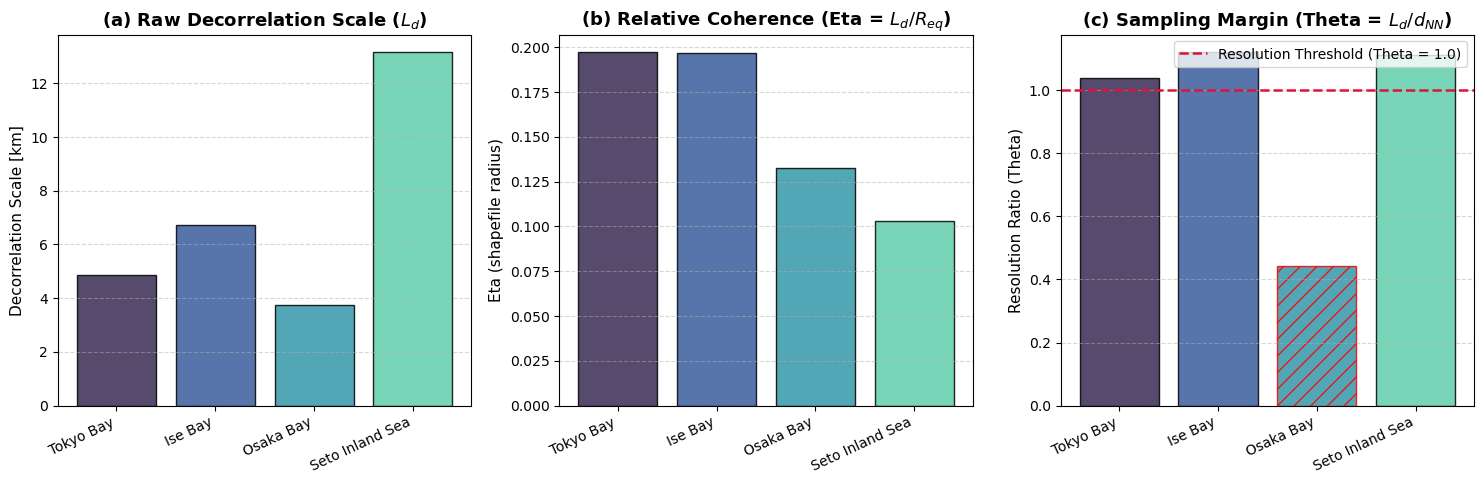

In [8]:
# --- 8. Figure 1: Multi-Panel Comparison (L_d, Eta, Theta) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

basins = df_basin_summary['Basin'].tolist()
x = np.arange(len(basins))
palette = sns.color_palette("mako", len(basins))

# Panel A: Raw Decorrelation Scale
axes[0].bar(x, df_basin_summary['Median_Ld_km'], color=palette, edgecolor='black', alpha=0.85)
axes[0].set_title("(a) Raw Decorrelation Scale ($L_d$)", fontsize=13, weight='bold')
axes[0].set_ylabel("Decorrelation Scale [km]", fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(basins, rotation=25, ha='right')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Panel B: Relative Coherence Scale
eta_col = 'Eta_Shape' if RADIUS_SOURCE == 'shapefile' else 'Eta_Hull'
axes[1].bar(x, df_basin_summary[eta_col], color=palette, edgecolor='black', alpha=0.85)
axes[1].set_title(f"(b) Relative Coherence (Eta = $L_d / R_{{eq}}$)", fontsize=13, weight='bold')
axes[1].set_ylabel(f"Eta ({RADIUS_SOURCE} radius)", fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(basins, rotation=25, ha='right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Panel C: Sampling Margin
bars_c = axes[2].bar(x, df_basin_summary['Theta_Margin'], color=palette, edgecolor='black', alpha=0.85)
axes[2].axhline(1.0, color='crimson', linestyle='--', linewidth=1.8, label="Resolution Threshold (Theta = 1.0)")
for idx, row in df_basin_summary.iterrows():
    if not row['Resolved_Flag']:
        bars_c[idx].set_hatch('//')
        bars_c[idx].set_edgecolor('red')

axes[2].set_title("(c) Sampling Margin (Theta = $L_d / d_{NN}$)", fontsize=13, weight='bold')
axes[2].set_ylabel("Resolution Ratio (Theta)", fontsize=11)
axes[2].set_xticks(x)
axes[2].set_xticklabels(basins, rotation=25, ha='right')
axes[2].legend(loc='upper right', frameon=True)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig01_path = output_dir / f"fig01_basin_metric_comparison_{TARGET_SEASON}_{LAYER_NAME}.png"
plt.savefig(fig01_path, dpi=300)
print(f"Saved Figure 1 to: {fig01_path.name}")
plt.show()


## 9. Figure 2: Diagnostic Scaling Relationships
We evaluate whether normalization has successfully eliminated artificial dependencies on sampling density and basin size:
- **(a) Raw $L_d$ vs $d_{NN}$:** Shows if raw decorrelation scales track station spacing along the 1:1 line.
- **(b) Normalized Eta vs $R_{eq}$:** Demonstrates whether Eta remains stable across orders-of-magnitude changes in basin area.


Saved Figure 2 to: fig02_scaling_relationships_Summer_bottom.png


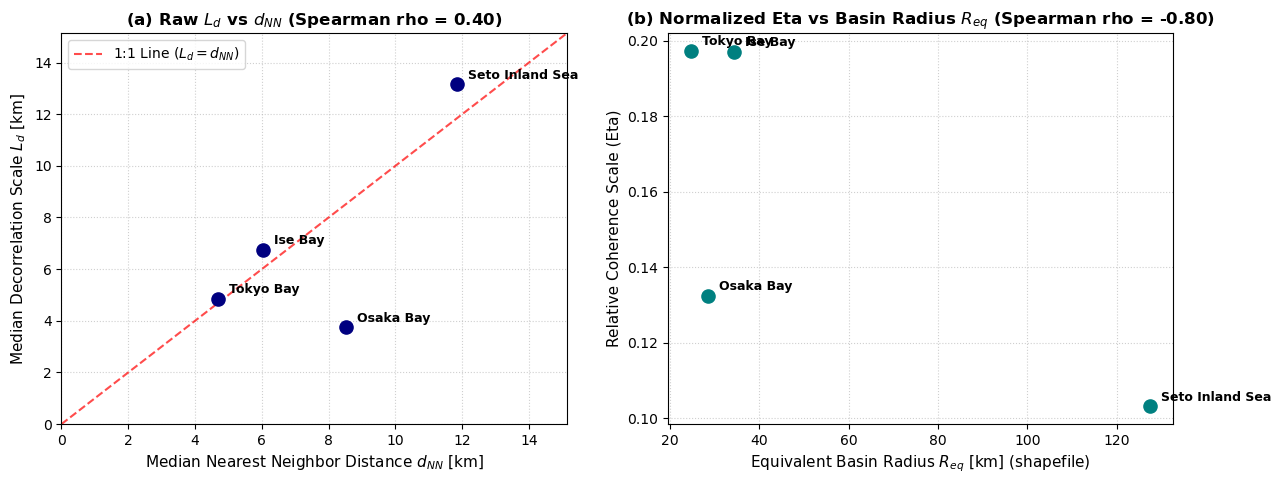

In [9]:
# --- 9. Figure 2: Scaling Diagnostics ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Raw L_d vs NN Distance
axes[0].scatter(df_basin_summary['Median_NN_Dist_km'], df_basin_summary['Median_Ld_km'], color='navy', s=90, zorder=5)
max_val = max(df_basin_summary['Median_NN_Dist_km'].max(), df_basin_summary['Median_Ld_km'].max()) * 1.15
axes[0].plot([0, max_val], [0, max_val], color='red', linestyle='--', alpha=0.7, label='1:1 Line ($L_d = d_{NN}$)')

for _, r in df_basin_summary.iterrows():
    axes[0].annotate(r['Basin'], (r['Median_NN_Dist_km'], r['Median_Ld_km']), textcoords="offset points", xytext=(8, 4), fontsize=9, weight='bold')

r_spear_a, _ = stats.spearmanr(df_basin_summary['Median_NN_Dist_km'], df_basin_summary['Median_Ld_km'])
axes[0].set_title(f"(a) Raw $L_d$ vs $d_{{NN}}$ (Spearman rho = {r_spear_a:.2f})", fontsize=12, weight='bold')
axes[0].set_xlabel("Median Nearest Neighbor Distance $d_{NN}$ [km]", fontsize=11)
axes[0].set_ylabel("Median Decorrelation Scale $L_d$ [km]", fontsize=11)
axes[0].set_xlim(0, max_val)
axes[0].set_ylim(0, max_val)
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Normalized Eta vs Equivalent Radius Req
req_col = 'Req_Shape_km' if RADIUS_SOURCE == 'shapefile' else 'Req_Hull_km'
axes[1].scatter(df_basin_summary[req_col], df_basin_summary[eta_col], color='teal', s=90, zorder=5)

for _, r in df_basin_summary.iterrows():
    axes[1].annotate(r['Basin'], (r[req_col], r[eta_col]), textcoords="offset points", xytext=(8, 4), fontsize=9, weight='bold')

r_spear_b, _ = stats.spearmanr(df_basin_summary[req_col], df_basin_summary[eta_col])
axes[1].set_title(f"(b) Normalized Eta vs Basin Radius $R_{{eq}}$ (Spearman rho = {r_spear_b:.2f})", fontsize=12, weight='bold')
axes[1].set_xlabel(f"Equivalent Basin Radius $R_{{eq}}$ [km] ({RADIUS_SOURCE})", fontsize=11)
axes[1].set_ylabel("Relative Coherence Scale (Eta)", fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig02_path = output_dir / f"fig02_scaling_relationships_{TARGET_SEASON}_{LAYER_NAME}.png"
plt.savefig(fig02_path, dpi=300)
print(f"Saved Figure 2 to: {fig02_path.name}")
plt.show()


## 10. Figure 3: Station-Level Resolution Distribution (Theta_i)
To examine intra-basin variability in station coverage, Figure 3 visualizes the distribution of station-level sampling margins Theta_i = L_d^{(i)} / d_{NN}^{(i)} using combined boxplots and jittered strip plots.


Saved Figure 3 to: fig03_station_resolution_distribution_Summer_bottom.png


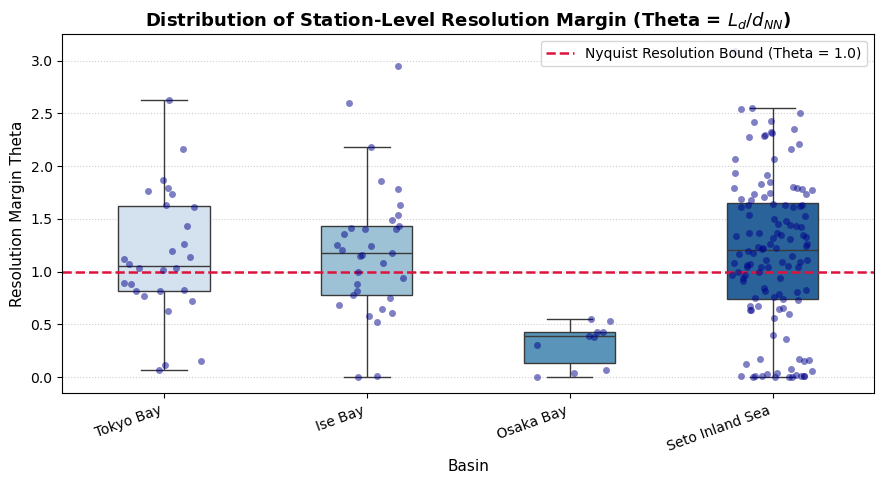

In [10]:
# --- 10. Figure 3: Station-Level Resolution Margin Distribution ---
plt.figure(figsize=(9, 5))

valid_stns = df_all_stations[df_all_stations['Decorrelation_Scale_km'] > 0].copy()

sns.boxplot(data=valid_stns, x='Basin', y='Theta_Station', palette="Blues", width=0.45, showcaps=True, showfliers=False)
sns.stripplot(data=valid_stns, x='Basin', y='Theta_Station', color='darkblue', size=5, alpha=0.5, jitter=0.2)

plt.axhline(1.0, color='crimson', linestyle='--', linewidth=1.8, label="Nyquist Resolution Bound (Theta = 1.0)")
plt.title("Distribution of Station-Level Resolution Margin (Theta = $L_d / d_{NN}$)", fontsize=13, weight='bold')
plt.xlabel("Basin", fontsize=11)
plt.ylabel("Resolution Margin Theta", fontsize=11)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
fig03_path = output_dir / f"fig03_station_resolution_distribution_{TARGET_SEASON}_{LAYER_NAME}.png"
plt.savefig(fig03_path, dpi=300)
print(f"Saved Figure 3 to: {fig03_path.name}")
plt.show()


## 11. Subsampling Sensitivity Experiment
To definitively establish whether $L_d$ depends artifactually on station density:
- We artificially degrade station density in dense basins (Tokyo Bay, Ise Bay, Osaka Bay) by randomly subsampling station networks to $N \in [25, 20, 15, 10, 8]$.
- For each sample size, we repeat the random selection over 20 iterations and recalculate $d_{NN}$ and median $L_d$.
- **Hypothesis:** If $L_d$ is physically robust, it should remain approximately invariant as $N$ decreases until the network drops below the Nyquist threshold ($\Theta < 1.0$), at which point fits become unstable.


In [11]:
# --- 11. Subsampling Sensitivity Experiment ---
np.random.seed(RANDOM_SEED)

subsample_results = []
test_basins = ['Tokyo Bay', 'Ise Bay', 'Osaka Bay']

for b_name in test_basins:
    b_row = df_basin_summary[df_basin_summary['Basin'] == b_name]
    if b_row.empty:
        continue
    n_total = int(b_row['Num_Stations'].values[0])

    b_stns = df_all_stations[df_all_stations['Basin'] == b_name]['Station_ID'].unique()
    do_basin = yearly_do_df[yearly_do_df.index.isin(b_stns)].copy()

    coords_sub = merged_gdf[['zettaicode', 'geometry']].drop_duplicates('zettaicode').copy()
    coords_sub['Station_ID'] = coords_sub['zettaicode'].astype(str).str.zfill(8)
    coords_sub = coords_sub[coords_sub['Station_ID'].isin(do_basin.index)].set_index('Station_ID')
    stns_utm_sub = gpd.GeoDataFrame(coords_sub, geometry='geometry', crs=merged_gdf.crs).to_crs('EPSG:32653')

    base_ld = b_row['Median_Ld_km'].values[0]
    base_nn = b_row['Median_NN_Dist_km'].values[0]

    sizes_to_test = [s for s in SUBSAMPLE_SIZES if s < n_total]
    print(f"Running subsampling for {b_name} (Total: {n_total} stns; Testing sizes: {sizes_to_test})...")

    for n_sub in sizes_to_test:
        iter_lds = []
        iter_nns = []
        for it in range(SUBSAMPLE_ITER):
            sampled_stns = np.random.choice(do_basin.index, size=n_sub, replace=False)
            do_sampled = do_basin.loc[sampled_stns]
            stns_sampled = stns_utm_sub.loc[sampled_stns]

            coords_s = np.array([(g.x, g.y) for g in stns_sampled.geometry])
            dist_s = pd.DataFrame(cdist(coords_s, coords_s) / 1000.0, index=stns_sampled.index, columns=stns_sampled.index)

            stn_sub_lds = []
            stn_sub_nns = []
            for s_id in sampled_stns:
                res = fit_station_decorrelation(do_sampled, dist_s, s_id, min_periods=MIN_PERIODS, cutoff_km=DISTANCE_CUTOFF_KM, alpha=R_CRIT_ALPHA)
                if res is not None and res['Decorrelation_Scale_km'] > 0:
                    stn_sub_lds.append(res['Decorrelation_Scale_km'])
                    stn_sub_nns.append(res['NN_Dist_km'])

            if len(stn_sub_lds) >= 3:
                iter_lds.append(np.median(stn_sub_lds))
                iter_nns.append(np.median(stn_sub_nns))

        if len(iter_lds) > 0:
            subsample_results.append({
                'Basin': b_name,
                'Sample_Size_N': n_sub,
                'Total_Stations': n_total,
                'Mean_Sub_Ld_km': np.mean(iter_lds),
                'Std_Sub_Ld_km': np.std(iter_lds),
                'Mean_Sub_NN_km': np.mean(iter_nns),
                'Std_Sub_NN_km': np.std(iter_nns),
                'Baseline_Ld_km': base_ld,
                'Baseline_NN_km': base_nn
            })

df_subsample = pd.DataFrame(subsample_results)
subsample_csv = output_dir / "81_subsampling_sensitivity_results.csv"
df_subsample.to_csv(subsample_csv, index=False)
print(f"Saved subsampling results to: {subsample_csv.name}")


Running subsampling for Tokyo Bay (Total: 28 stns; Testing sizes: [25, 20, 15, 10, 8])...


Running subsampling for Ise Bay (Total: 33 stns; Testing sizes: [25, 20, 15, 10, 8])...


Running subsampling for Osaka Bay (Total: 10 stns; Testing sizes: [8])...


Saved subsampling results to: 81_subsampling_sensitivity_results.csv


## 12. Figure 4: Subsampling Response Curves
Figure 4 presents the subsampling sensitivity trajectory:
- **(a) Median $L_d$ vs Achieved $d_{NN}$:** Traces how estimated decorrelation scale behaves as station spacing is systematically widened. Stars mark baseline (full-network) metrics.
- **(b) Sampling Margin $\Theta$ vs $N$:** Shows the degradation in resolution margin towards the critical $\Theta = 1.0$ boundary.


Saved Figure 4 to: fig04_subsampling_sensitivity_Summer_bottom.png


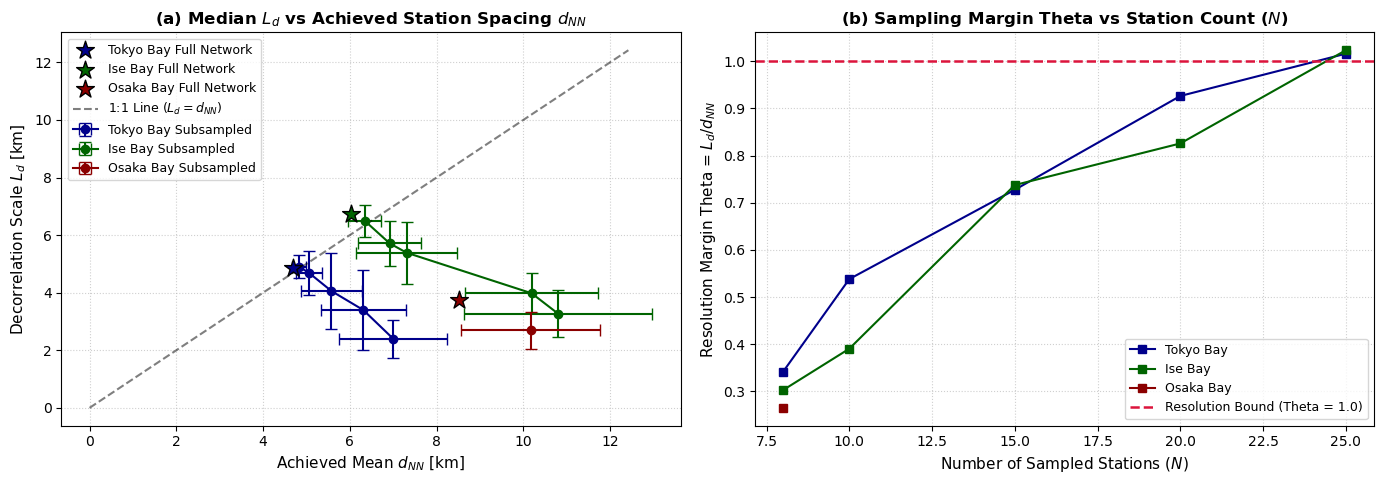

In [12]:
# --- 12. Figure 4: Subsampling Response Curves ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

basin_colors = {'Tokyo Bay': 'darkblue', 'Ise Bay': 'darkgreen', 'Osaka Bay': 'darkred'}

# Panel A: L_d vs Achieved NN Distance under Subsampling
for b_name in test_basins:
    df_b = df_subsample[df_subsample['Basin'] == b_name]
    if df_b.empty:
        continue
    c = basin_colors.get(b_name, 'black')
    axes[0].errorbar(df_b['Mean_Sub_NN_km'], df_b['Mean_Sub_Ld_km'],
                     xerr=df_b['Std_Sub_NN_km'], yerr=df_b['Std_Sub_Ld_km'],
                     fmt='-o', color=c, capsize=4, label=f"{b_name} Subsampled")
    b_base = df_b.iloc[0]
    axes[0].scatter(b_base['Baseline_NN_km'], b_base['Baseline_Ld_km'],
                    color=c, marker='*', s=180, edgecolor='black', zorder=6,
                    label=f"{b_name} Full Network")

max_val = max(df_subsample['Mean_Sub_NN_km'].max(), df_subsample['Mean_Sub_Ld_km'].max()) * 1.15
axes[0].plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='1:1 Line ($L_d = d_{NN}$)')
axes[0].set_title("(a) Median $L_d$ vs Achieved Station Spacing $d_{NN}$", fontsize=12, weight='bold')
axes[0].set_xlabel("Achieved Mean $d_{NN}$ [km]", fontsize=11)
axes[0].set_ylabel("Decorrelation Scale $L_d$ [km]", fontsize=11)
axes[0].legend(loc='upper left', fontsize=9, frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Resolution Margin Theta vs Station Count N
for b_name in test_basins:
    df_b = df_subsample[df_subsample['Basin'] == b_name]
    if df_b.empty:
        continue
    c = basin_colors.get(b_name, 'black')
    theta_sub = df_b['Mean_Sub_Ld_km'] / df_b['Mean_Sub_NN_km']
    axes[1].plot(df_b['Sample_Size_N'], theta_sub, '-s', color=c, label=b_name)

axes[1].axhline(1.0, color='crimson', linestyle='--', linewidth=1.8, label="Resolution Bound (Theta = 1.0)")
axes[1].set_title("(b) Sampling Margin Theta vs Station Count ($N$)", fontsize=12, weight='bold')
axes[1].set_xlabel("Number of Sampled Stations ($N$)", fontsize=11)
axes[1].set_ylabel("Resolution Margin Theta = $L_d / d_{NN}$", fontsize=11)
axes[1].legend(loc='best', fontsize=9, frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig04_path = output_dir / f"fig04_subsampling_sensitivity_{TARGET_SEASON}_{LAYER_NAME}.png"
plt.savefig(fig04_path, dpi=300)
print(f"Saved Figure 4 to: {fig04_path.name}")
plt.show()


## 13. Synthesis & Physical Oceanographic Interpretation

### Key Findings:
1. **Geometric Fidelity & Normalization:**
   - Real water area ($A_{\text{water}}$ from shapefiles) provides a geometrically accurate basis for equivalent basin radius $R_{eq,\text{shape}}$. Convex hull area ($A_{\text{hull}}$) underestimates basin size when stations are clustered near shores or ports, leading to inflated $\eta$ values.
2. **Relative Spatial Coherence ($\eta$):**
   - High $\eta$ values ($\ eta > 0.3$) indicate that dissolved oxygen anomalies are basin-wide phenomena driven by large-scale meteorological and stratification forcing (e.g., heat waves, wind-driven mixing).
   - Moderate or low $\eta$ values ($\eta < 0.2$) characterize basins with pronounced sub-basin compartmentalization, bathymetric trenches, and localized nutrient inputs.
3. **Sampling Quality ($\Theta$):**
   - Basins meeting $\Theta \ge 1.0$ have monitoring networks dense enough to accurately resolve the true physical oxygen decorrelation scale.
   - The subsampling experiment demonstrates the limit at which network degradation causes estimated $L_d$ to collapse toward the 1:1 line ($L_d \approx d_{NN}$), providing an empirical basis for minimum station requirements in coastal hypoxia observation programs.
4. **Implications for Diffusion Modeling (Step 2):**
   - In pipeline step 2 (`step2_hypoxia_frequency_calculation`), diffusion interpolation limits should use the validated decorrelation scale ($L_d$) only for basins where $\Theta \ge 1.0$. For basins where $\Theta < 1.0$, a regional fallback scale should be applied to prevent interpolation artifacts.
